## Histogramm

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/checking-logs.sqlite")
query = """
    SELECT
        timestamp
    FROM
        checker
    WHERE
        uid LIKE 'user_%'
"""
df = pd.read_sql(query, conn, parse_dates=['timestamp'])
conn.close()

## data processing

In [2]:
df['hour'] = df['timestamp'].dt.hour
df['daytype'] = df['timestamp'].dt.dayofweek.apply(lambda x: 'working day' if x < 5 else 'weekend')

workday_hours = df[df['daytype']=='working day']['hour']
wekkend_hours = df[df['daytype']=='weekend']['hour']
len(workday_hours)

2037

In [4]:
len(wekkend_hours)

1170

## histogramm

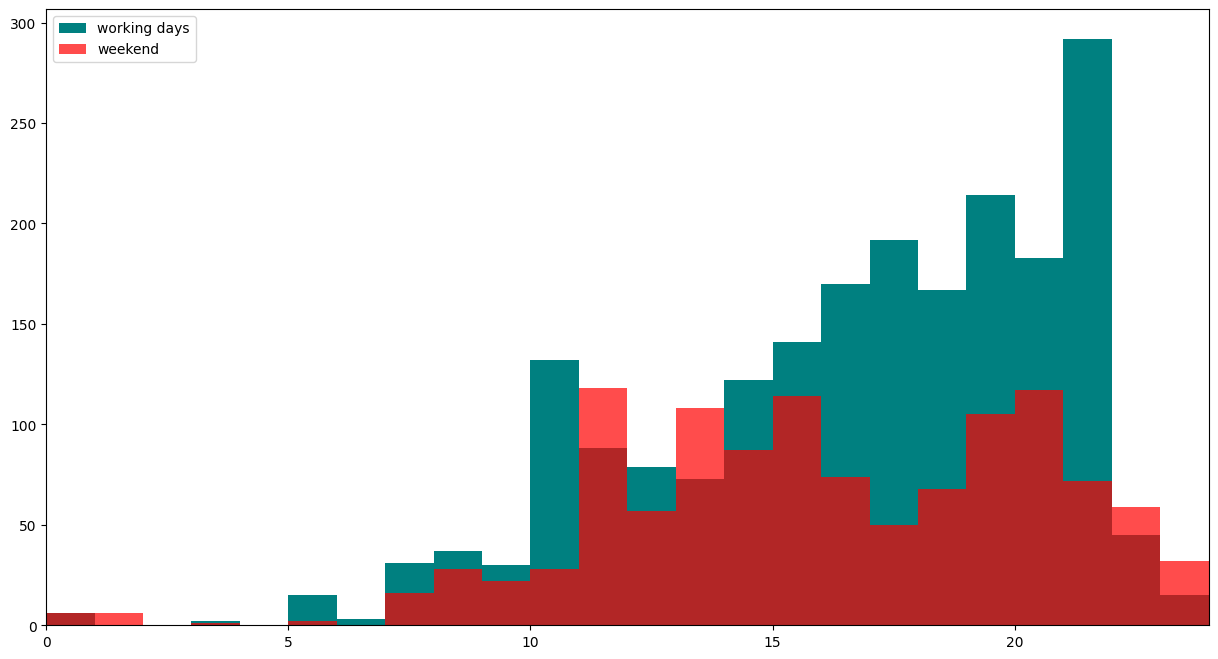

In [3]:
fig, ax = plt.subplots(figsize=(15,8))

ax.hist(workday_hours, bins=24, range=(0, 24), color='teal', label='working days')
ax.hist(wekkend_hours, bins=24, range=(0, 24), color='red', alpha=0.7, label='weekend')
ax.set_xlim(0, 24)
ax.legend()
plt.show()

#### Are there hours when the total number of commits was higher on weekends than on working days?

Answer with top 4: 11, 13, 22, 23